# Exercise - Classification using k-Nearest Neighbors
---

In this notebook we will perform classification on **handwritten digits** using the **k-nearest neighbor** algorithm. 

The original dataset is available from [UCI machine learning repository](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits). In `scikit-learn`, only the test data from the original data was used (for unknown reason) -- if you want to try, you can also get more data from the link above.

In fact, this is a much smaller (and lower resolution) version of the well-known [MNIST dataset](http://yann.lecun.com/exdb/mnist/)

First, our imports:

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA



## Data Understanding and Preprocessing

Let's load the data first and then have a look at the structure. Frankly, every image is 8x8 pixels, stored in sequence in a 64 dimensional vector. For the grey values 0...16 are used (whyever -- 0...15 would make much more sense). More details, also about the preprocessing can be found in the [docs](https://scikit-learn.org/stable/datasets/toy_dataset.html#digits-dataset).

In [3]:
digits = load_digits()

X = digits.data
y = digits.target

print('Gray values:',(X.min(), X.max())) # this is strange ... 0-15 == 4 bit would be much more useful
print('Shape:',X.shape)

print('Example of digit',y[0],':',X[0])

Gray values: (np.float64(0.0), np.float64(16.0))
Shape: (1797, 64)
Example of digit 0 : [ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


Now, let's plot first 10 images (they contain all classes). We need to reshape to 8x8 pixel (1D (64 features) -> 2D)

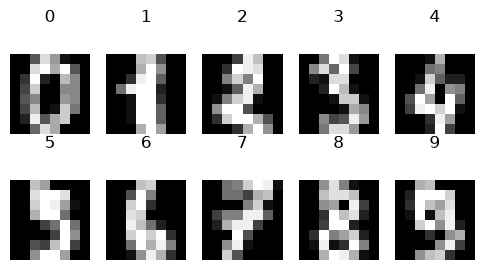

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(6, 3), )
for i in range(10):
    ax = axes[i//5, i%5]
    ax.matshow(X[i, ...].reshape(8,8),
               cmap=plt.cm.gray)
    ax.set_axis_off()
    ax.set_title(y[i])
plt.show()

Looks unusual to us, lets invert the grey value such that we have black on white. This can be done using an appropriate color map, and zoom out a bit.

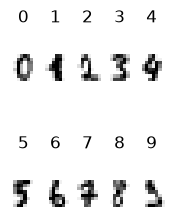

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(2, 3), )
for i in range(10): 
    ax = axes[i//5, i%5]
    ax.matshow(X[i+10, ...].reshape(8,8), # plot next 10 to see different examples....
               cmap=plt.cm.gray_r)
    ax.set_axis_off()
    ax.set_title(y[i+10])
plt.show()

Are the classes equally distributed?

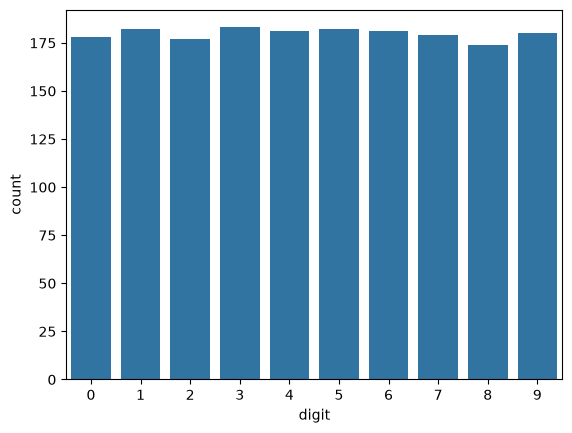

In [6]:
tmp = pd.DataFrame(y, columns=['digit'])

sns.countplot(x='digit', data=tmp)
plt.show()

They are! 

Now, let's split into training and test data

In [7]:
(X_train, X_test, y_train, y_test) = train_test_split(X, y, test_size=.2, stratify=y, random_state=0)

## Modelling: Classification with k-NN

Now apply a k-NN and measure accuracy on the test set.

In [8]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
accuracy_score(y_test,y_pred)

0.9777777777777777

## Deployment

Let's draw a "1". We make it good looking such that it can be classified correctly...

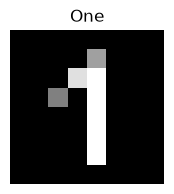

In [9]:
one = np.zeros((8, 8)) # The image values are in [0, 16].
one[1:-1, 4] = 16  # the |
one[2, 3] = 14 # the front part
one[3, 2] = 8 # the front part
one[1, 4] = 10 # blur the top a bit

fig, ax = plt.subplots(1, 1, figsize=(2, 2))
ax.imshow(one, interpolation='none', cmap=plt.cm.gray)
ax.grid(False)
ax.set_axis_off()
ax.set_title("One")
plt.show()

In [10]:
# And check if it is recognized! 
# reshape to 1D array
print('This is a', knn.predict(one.reshape((1,-1)))[0])

This is a 1


<h4><span style="color:blue">1. Plot a confusion matrix</span></h4>

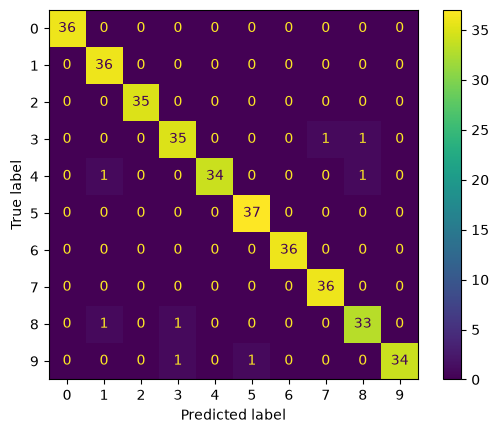

In [13]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()
plt.show()

<h4><span style="color:blue">2. Now it is your turn to tune the hyperparameters. Can you increase the accuracy?</span></h4>

**Notes:**
* This time, use the Minkowski metric and alternate the parameter p (have a look at the documentation) this includes euclidean and manhatten distance
* Make sure not to use the testset fur tuning!
* Also try to add a PCA as a preprocessing step (and also tune hyperparameters, same way as above)! Is it better with PCA?

In [15]:
# Hyperparameter tuning using p, k and weights.
## careful: this takes quite some time!
# Modell erstellen
knn = KNeighborsClassifier(metric='minkowski')

# Hyperparameter definieren
param_grid = {
    'n_neighbors': range(1, 31),
    'p': [1, 2, 3, 4, 5],
    'weights': ['uniform', 'distance']
}

# Grid Search mit 5-fold Cross-Validation
grid_search = GridSearchCV(
    knn,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Nur mit Trainingsdaten optimieren!
grid_search.fit(X_train, y_train)

# Beste Parameter anzeigen
print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", grid_search.best_score_)

Best parameters: {'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best CV accuracy: 0.9881629887727449


In [16]:
# Create new model with full training data and test it.
# Neues Modell mit den besten Parametern erstellen
best_knn = KNeighborsClassifier(
    n_neighbors=grid_search.best_params_['n_neighbors'],
    p=grid_search.best_params_['p'],
    weights=grid_search.best_params_['weights']
)

# Mit allen Trainingsdaten trainieren
best_knn.fit(X_train, y_train)

# Vorhersagen für die Testdaten
y_pred = best_knn.predict(X_test)

# Accuracy berechnen
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Test Accuracy: 0.9861111111111112


In [18]:
# Now with PCA, but using k=1...10 only.
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('knn', KNeighborsClassifier(metric='minkowski'))
])

param_grid = {
    'pca__n_components': [2, 5, 10],
    'knn__n_neighbors': range(1, 11),
    'knn__p': [1, 2, 3, 4, 5],
    'knn__weights': ['uniform', 'distance']
}

grid_pca = GridSearchCV(
    pipe,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_pca.fit(X_train, y_train)

best_model_pca = grid_pca.best_estimator_

best_model_pca.fit(X_train, y_train)

y_pred_pca = best_model_pca.predict(X_test)

print("Accuracy with PCA:",
      accuracy_score(y_test, y_pred_pca))

print("Best parameters:", grid_pca.best_params_)
print("Best CV accuracy:", grid_pca.best_score_)

print("Accuracy without PCA:",
      accuracy_score(y_test, y_pred))

print("Accuracy with PCA:",
      accuracy_score(y_test, y_pred_pca))

Accuracy with PCA: 0.9305555555555556
Best parameters: {'knn__n_neighbors': 6, 'knn__p': 1, 'knn__weights': 'distance', 'pca__n_components': 10}
Best CV accuracy: 0.9338753387533876
Accuracy without PCA: 0.9861111111111112
Accuracy with PCA: 0.9305555555555556


<h4><span style="color:blue">3. Plot some(or all, if there are not too many) digits, which are incorrectly classified, also showing their true class.</span></h4>

Number of misclassified digits: 5


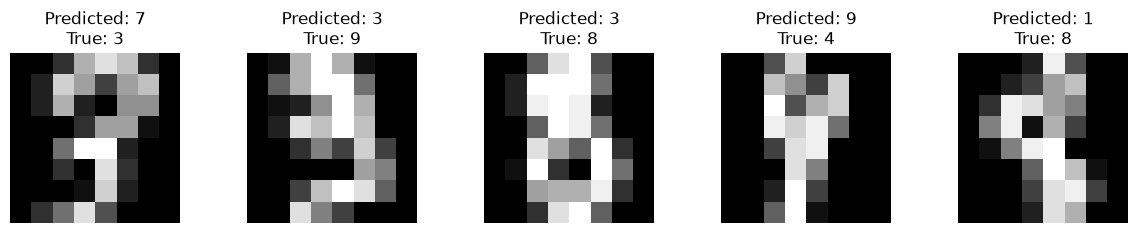

In [20]:
# Falsch klassifizierte Ziffern finden
misclassified = np.where(y_test != y_pred)[0]

print("Number of misclassified digits:", len(misclassified))

# Maximal 20 falsche Klassifikationen anzeigen
n = min(len(misclassified), 20)

plt.figure(figsize=(12, 8))

for i in range(n):
    idx = misclassified[i]

    plt.subplot(4, 5, i + 1)
    plt.imshow(X_test[idx].reshape(8, 8), cmap='gray')
    plt.title(f"Predicted: {y_pred[idx]}\nTrue: {y_test[idx]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

<h4><span style="color:blue">4. Try to draw a digit, which your classifier fails to recognize, but a human can easily classify!</span></h4>

**Note**: You can also modify an existing example. As a hint to find a solution: Re-think of how k-NN works and how you could potentially *manipulate* an image, such that it is hard to find a "neighbor"...

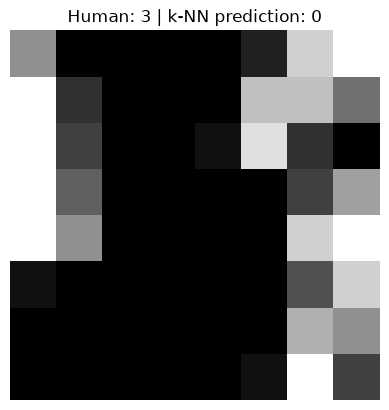

Predicted digit: 0


In [25]:

ax.set_xlim(0, 8)
ax.set_ylim(8, 0)
ax.set_xticks(range(9))
ax.set_yticks(range(9))
ax.grid(True)

ax.set_title("Draw a digit (close the plot when finished)")

points = []

def draw(event):
    if event.xdata is not None and event.ydata is not None:
        points.append((event.xdata, event.ydata))
        ax.plot(event.xdata, event.ydata, 'ko')
        fig.canvas.draw()

fig.canvas.mpl_connect('motion_notify_event', draw)
plt.show()

# Ein Beispiel aus dem Testdatensatz auswählen
digit = X_test[0].reshape(8, 8).copy()

# Pixelwerte manipulieren
digit = np.roll(digit, 3, axis=1)

# Bild anzeigen
plt.imshow(digit, cmap='gray')
plt.title("Human: 3 | k-NN prediction: 0")
plt.axis('off')
plt.show()

# Bild wieder in eine Zeile mit 64 Features umwandeln
digit_input = digit.reshape(1, -1)

# Vorhersage
prediction = grid_search.best_estimator_.predict(digit_input)

print("Predicted digit:", prediction[0])